In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy import ndimage
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

FEATURES_DIR = Path("features")
IMAGE_SIZE = (256, 192)
AQI_CLASSES = ["0–50", "51–100", "101–150", "151–200", "201–300", "301–600"]

data = pd.read_csv(FEATURES_DIR / "clean_metadata.csv")
print(data.shape)
data.groupby("split")["pm25"].describe().round(1)

(11096, 21)


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,2920.0,119.4,81.5,2.0,54.0,114.0,165.0,416.0
train,8176.0,121.8,88.4,1.0,54.0,111.0,164.0,530.0


In [2]:
def load_image(path):
    image = Image.open(path).convert("RGB").resize(IMAGE_SIZE)
    return np.asarray(image, dtype=np.float32) / 255


def dark_channel(rgb):
    return ndimage.minimum_filter(rgb.min(axis=2), size=7)


def saturation(rgb):
    brightest = rgb.max(axis=2)
    darkest = rgb.min(axis=2)
    return (brightest - darkest) / (brightest + 1e-6)


def brightness(rgb):
    return rgb.max(axis=2)


def edges(rgb):
    gray = rgb.mean(axis=2)
    return np.hypot(ndimage.sobel(gray, axis=0), ndimage.sobel(gray, axis=1))


def local_contrast(rgb):
    gray = rgb.mean(axis=2)
    mean = ndimage.uniform_filter(gray, size=7)
    mean_of_squares = ndimage.uniform_filter(gray ** 2, size=7)
    return np.sqrt(np.clip(mean_of_squares - mean ** 2, 0, None))


def blue_ratio(rgb):
    return rgb[:, :, 2] / (rgb.sum(axis=2) + 1e-6)


FILTERS = {
    "dark_channel": dark_channel,
    "saturation": saturation,
    "brightness": brightness,
    "edges": edges,
    "local_contrast": local_contrast,
    "blue_ratio": blue_ratio,
}

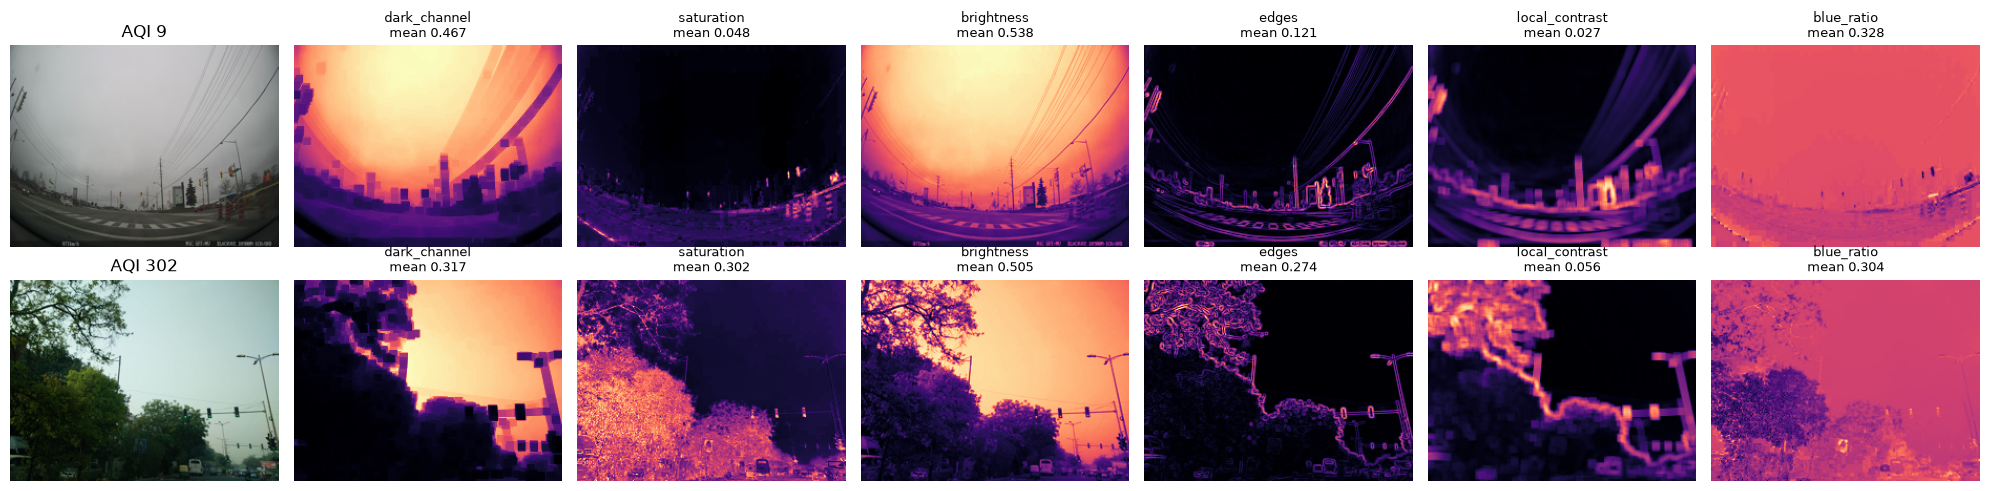

In [3]:
clean_example = data[(data["split"] == "train") & (data["pm25_bin"] == "0–50")].sample(1, random_state=1).iloc[0]
polluted_example = data[(data["split"] == "train") & (data["pm25_bin"] == "301–600")].sample(1, random_state=1).iloc[0]

fig, axes = plt.subplots(2, len(FILTERS) + 1, figsize=(20, 5))
for row, example in enumerate([clean_example, polluted_example]):
    rgb = load_image(example["image_path"])
    axes[row, 0].imshow(rgb)
    axes[row, 0].set_title(f"AQI {example['pm25']:.0f}")
    for column, (name, apply_filter) in enumerate(FILTERS.items(), start=1):
        response = apply_filter(rgb)
        axes[row, column].imshow(response, cmap="magma")
        axes[row, column].set_title(f"{name}\nmean {response.mean():.3f}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
BANDS = {"top": slice(0, 64), "middle": slice(64, 128), "bottom": slice(128, 192)}


def extract_features(path):
    rgb = load_image(path)
    features = {}
    for filter_name, apply_filter in FILTERS.items():
        response = apply_filter(rgb)
        for band_name, rows in BANDS.items():
            values = response[rows]
            features[f"{filter_name}_{band_name}_mean"] = float(values.mean())
            features[f"{filter_name}_{band_name}_p10"] = float(np.percentile(values, 10))
            features[f"{filter_name}_{band_name}_p90"] = float(np.percentile(values, 90))
    return features


example_features = extract_features(clean_example["image_path"])
print(len(example_features), "features per image")
dict(list(example_features.items())[:9])

54 features per image


{'dark_channel_top_mean': 0.674180269241333,
 'dark_channel_top_p10': 0.5098039507865906,
 'dark_channel_top_p90': 0.7843137383460999,
 'dark_channel_middle_mean': 0.5554972887039185,
 'dark_channel_middle_p10': 0.30980393290519714,
 'dark_channel_middle_p90': 0.729411780834198,
 'dark_channel_bottom_mean': 0.17120841145515442,
 'dark_channel_bottom_p10': 0.07058823853731155,
 'dark_channel_bottom_p90': 0.3607843220233917}

In [5]:
rows = []
for index, path in enumerate(data["image_path"]):
    rows.append(extract_features(path))
    if index % 2000 == 0:
        print(f"{index} / {len(data)}")

band_features = pd.DataFrame(rows)
feature_names = list(band_features.columns)
features = pd.concat([data[["image_id", "split", "station_id", "region", "pm25", "pm25_bin"]], band_features], axis=1)
features.to_csv(FEATURES_DIR / "band_filter_features.csv", index=False)

train = features[features["split"] == "train"].copy()
test = features[features["split"] == "test"].copy()
print(features.shape, "| features per image:", len(feature_names))

0 / 11096
2000 / 11096
4000 / 11096
6000 / 11096
8000 / 11096
10000 / 11096
(11096, 60) | features per image: 54


In [6]:
ranking = train[feature_names].corrwith(train["pm25"], method="spearman").rename("spearman_rho").to_frame()
ranking["abs_rho"] = ranking["spearman_rho"].abs()
ranking[["filter", "band", "statistic"]] = [name.rsplit("_", 2) for name in ranking.index]
ranking = ranking.sort_values("abs_rho", ascending=False)
ranking.head(15).round(3)

,spearman_rho,abs_rho,filter,band,statistic
saturation_top_p90,-0.264,0.264,saturation,top,p90
edges_top_p10,-0.263,0.263,edges,top,p10
local_contrast_top_p10,-0.261,0.261,local_contrast,top,p10
blue_ratio_top_p90,-0.253,0.253,blue_ratio,top,p90
saturation_middle_p90,-0.248,0.248,saturation,middle,p90
saturation_top_mean,-0.243,0.243,saturation,top,mean
saturation_middle_mean,-0.238,0.238,saturation,middle,mean
dark_channel_top_mean,0.225,0.225,dark_channel,top,mean
dark_channel_top_p90,0.210,0.210,dark_channel,top,p90
blue_ratio_top_mean,-0.202,0.202,blue_ratio,top,mean


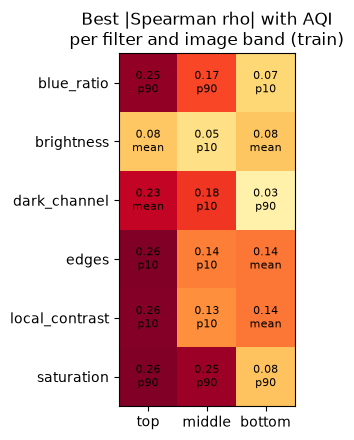

In [7]:
rho_table = ranking.pivot_table(index="filter", columns="band", values="abs_rho", aggfunc="max")[list(BANDS)]
best_statistic = ranking.loc[ranking.groupby(["filter", "band"])["abs_rho"].idxmax()].set_index(["filter", "band"])["statistic"]

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(rho_table.to_numpy(), cmap="YlOrRd", vmin=0)
ax.set_xticks(range(len(BANDS)), rho_table.columns)
ax.set_yticks(range(len(rho_table)), rho_table.index)
ax.set_title("Best |Spearman rho| with AQI\nper filter and image band (train)")
ax.grid(False)
for (row, column), value in np.ndenumerate(rho_table.to_numpy()):
    statistic = best_statistic[(rho_table.index[row], rho_table.columns[column])]
    ax.text(column, row, f"{value:.2f}\n{statistic}", ha="center", va="center", fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
cv = GroupKFold(n_splits=5, shuffle=True, random_state=42)
model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))


def regression_scores(true, predicted):
    return {
        "MAE": mean_absolute_error(true, predicted),
        "RMSE": np.sqrt(mean_squared_error(true, predicted)),
        "R2": r2_score(true, predicted),
        "Spearman": pd.Series(true).corr(pd.Series(predicted), method="spearman"),
    }


def cv_scores(columns):
    predicted = cross_val_predict(model, train[columns], train["pm25"], groups=train["station_id"], cv=cv)
    return regression_scores(train["pm25"].to_numpy(), predicted)


def test_scores(columns):
    model.fit(train[columns], train["pm25"])
    predicted = model.predict(test[columns])
    return regression_scores(test["pm25"].to_numpy(), predicted), predicted


median_prediction = np.full(len(test), train["pm25"].median())
baseline = {
    "MAE": mean_absolute_error(test["pm25"], median_prediction),
    "RMSE": np.sqrt(mean_squared_error(test["pm25"], median_prediction)),
    "R2": r2_score(test["pm25"], median_prediction),
    "Spearman": np.nan,
}
print("baseline on test (always predict the train median AQI):", {name: round(float(value), 2) for name, value in baseline.items()})

baseline on test (always predict the train median AQI): {'MAE': 63.64, 'RMSE': 81.88, 'R2': -0.01, 'Spearman': nan}


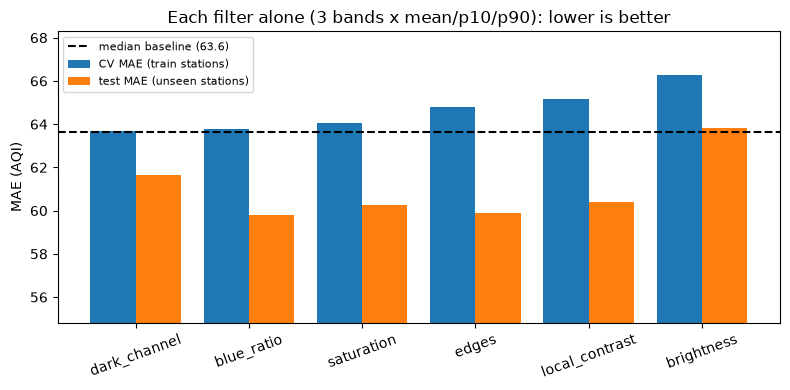

,cv_MAE,cv_R2,test_MAE,test_R2,test_Spearman
filter,,,,,
dark_channel,63.662,0.047,61.659,0.029,0.226
blue_ratio,63.775,0.044,59.803,0.073,0.311
saturation,64.034,0.033,60.254,0.049,0.269
edges,64.798,0.023,59.887,0.092,0.357
local_contrast,65.179,0.016,60.380,0.079,0.365
brightness,66.296,-0.001,63.826,-0.009,0.131


In [9]:
rows = []
for filter_name in FILTERS:
    columns = [name for name in feature_names if name.startswith(filter_name + "_")]
    cv_result = cv_scores(columns)
    test_result, _ = test_scores(columns)
    rows.append({
        "filter": filter_name,
        "cv_MAE": cv_result["MAE"],
        "cv_R2": cv_result["R2"],
        "test_MAE": test_result["MAE"],
        "test_R2": test_result["R2"],
        "test_Spearman": test_result["Spearman"],
    })
filter_comparison = pd.DataFrame(rows).set_index("filter").sort_values("cv_MAE")

fig, ax = plt.subplots(figsize=(8, 4))
positions = np.arange(len(filter_comparison))
ax.bar(positions - 0.2, filter_comparison["cv_MAE"], width=0.4, label="CV MAE (train stations)")
ax.bar(positions + 0.2, filter_comparison["test_MAE"], width=0.4, label="test MAE (unseen stations)")
ax.axhline(baseline["MAE"], color="black", linestyle="--", label=f"median baseline ({baseline['MAE']:.1f})")
ax.set_xticks(positions, filter_comparison.index, rotation=20)
ax.set(ylabel="MAE (AQI)", ylim=(filter_comparison[["cv_MAE", "test_MAE"]].min().min() - 5, max(filter_comparison[["cv_MAE", "test_MAE"]].max().max(), baseline["MAE"]) + 2), title="Each filter alone (3 bands x mean/p10/p90): lower is better")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
filter_comparison.round(3)

In [10]:
selected = []
best_mae = np.inf
while len(selected) < 6:
    candidate_mae = {name: cv_scores(selected + [name])["MAE"] for name in feature_names if name not in selected}
    best_name = min(candidate_mae, key=candidate_mae.get)
    if best_mae - candidate_mae[best_name] < 0.5:
        break
    selected.append(best_name)
    best_mae = candidate_mae[best_name]
    print(f"{len(selected)} features: + {best_name:24s} CV MAE {best_mae:.2f}")

print(f"all {len(feature_names)} features:{'':10s} CV MAE {cv_scores(feature_names)['MAE']:.2f}")

1 features: + saturation_top_p90       CV MAE 64.36
2 features: + edges_top_p10            CV MAE 63.38
3 features: + dark_channel_middle_p10  CV MAE 62.65
4 features: + brightness_middle_p10    CV MAE 62.00
5 features: + local_contrast_top_p10   CV MAE 61.46
all 54 features:           CV MAE 59.52


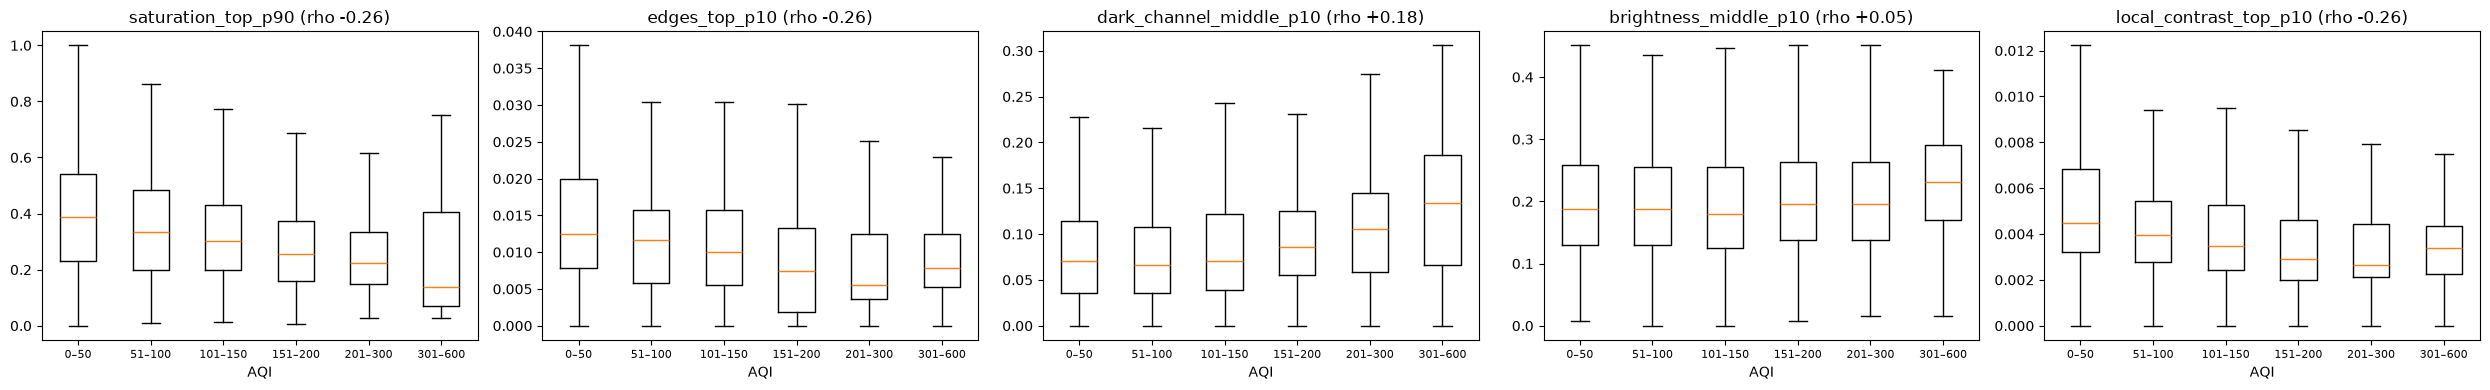

In [11]:
fig, axes = plt.subplots(1, len(selected), figsize=(5 * len(selected), 4))
for ax, name in zip(np.atleast_1d(axes), selected):
    ax.boxplot([train.loc[train["pm25_bin"] == aqi_bin, name] for aqi_bin in AQI_CLASSES], tick_labels=AQI_CLASSES, showfliers=False)
    ax.set(title=f"{name} (rho {ranking.loc[name, 'spearman_rho']:+.2f})", xlabel="AQI")
    ax.tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()

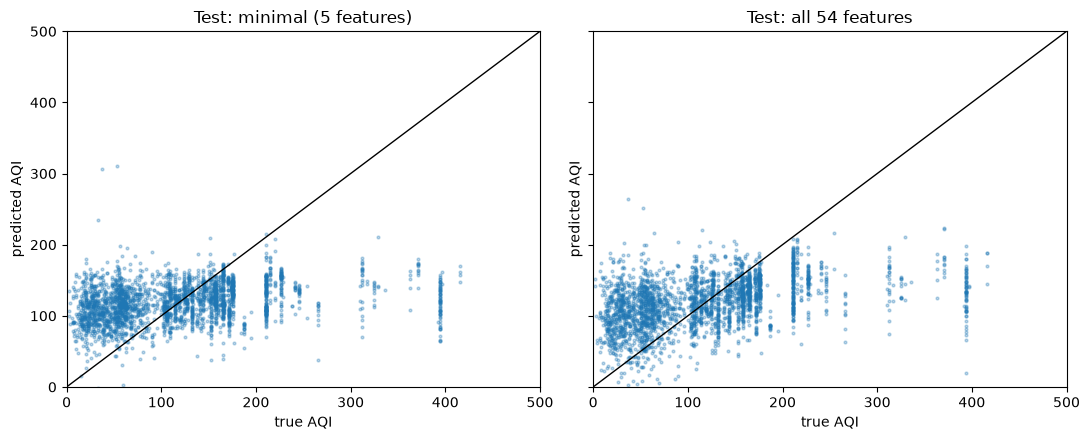

,MAE,RMSE,R2,Spearman
train median (no image),63.636,81.880,-0.011,NaN
minimal (5 features),58.554,77.871,0.086,0.341
all 54 features,54.892,73.969,0.175,0.463


In [12]:
minimal_result, minimal_predicted = test_scores(selected)
all_result, all_predicted = test_scores(feature_names)
results = pd.DataFrame({
    "train median (no image)": baseline,
    f"minimal ({len(selected)} features)": minimal_result,
    f"all {len(feature_names)} features": all_result,
}).T

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, predicted, title in [(axes[0], minimal_predicted, f"minimal ({len(selected)} features)"), (axes[1], all_predicted, f"all {len(feature_names)} features")]:
    ax.scatter(test["pm25"], predicted, s=4, alpha=0.3)
    ax.plot([0, 500], [0, 500], color="black", linewidth=1)
    ax.set(xlabel="true AQI", ylabel="predicted AQI", title=f"Test: {title}", xlim=(0, 500), ylim=(0, 500))
plt.tight_layout()
plt.show()
results.round(3)

In [13]:
features[["image_id", "split", "station_id", "pm25"] + selected].to_csv(FEATURES_DIR / "minimal_features.csv", index=False)

feature_spec = {
    "target": "pm25 (US AQI), regression",
    "image_size": IMAGE_SIZE,
    "bands": {name: [rows.start, rows.stop] for name, rows in BANDS.items()},
    "filters": list(FILTERS),
    "statistics_per_band": ["mean", "p10", "p90"],
    "model": "StandardScaler + Ridge(alpha=1.0) on raw AQI",
    "selected_features": selected,
    "filter_comparison": filter_comparison.round(4).reset_index().to_dict(orient="records"),
    "test_scores": results.round(4).reset_index(names="feature_set").to_dict(orient="records"),
}
(FEATURES_DIR / "minimal_feature_spec.json").write_text(json.dumps(feature_spec, indent=2))
print("saved:", selected)

saved: ['saturation_top_p90', 'edges_top_p10', 'dark_channel_middle_p10', 'brightness_middle_p10', 'local_contrast_top_p10']


In [17]:
from sklearn.neural_network import MLPRegressor

latitude = np.radians(data["latitude"])
longitude = np.radians(data["longitude"])
metadata = pd.DataFrame({
    "image_id": data["image_id"],
    "month_sin": np.sin(2 * np.pi * data["month"] / 12),
    "month_cos": np.cos(2 * np.pi * data["month"] / 12),
    "geo_x": np.cos(latitude) * np.cos(longitude),
    "geo_y": np.cos(latitude) * np.sin(longitude),
    "geo_z": np.sin(latitude),
    "year": data["year"],
})
metadata_columns = list(metadata.columns[1:])
train_nn = train.merge(metadata, on="image_id", how="left")
test_nn = test.merge(metadata, on="image_id", how="left")


def make_mlp():
    return make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True, max_iter=500, random_state=42))


def evaluate_mlp(columns):
    cv_predicted = cross_val_predict(make_mlp(), train_nn[columns], train_nn["pm25"], groups=train_nn["station_id"], cv=cv)
    test_predicted = make_mlp().fit(train_nn[columns], train_nn["pm25"]).predict(test_nn[columns])
    cv_result = regression_scores(train_nn["pm25"].to_numpy(), cv_predicted)
    test_result = regression_scores(test_nn["pm25"].to_numpy(), test_predicted)
    return {"cv_MAE": cv_result["MAE"], "cv_R2": cv_result["R2"], **{f"test_{name}": value for name, value in test_result.items()}}


mlp_results = pd.DataFrame({
    f"minimal ({len(selected)} image features)": evaluate_mlp(selected),
    f"all {len(feature_names)} image features": evaluate_mlp(feature_names),
    "metadata only (month, location, year)": evaluate_mlp(metadata_columns),
    "image features + metadata": evaluate_mlp(feature_names + metadata_columns),
}).T
mlp_results.round(4).to_csv(FEATURES_DIR / "mlp_results.csv")
mlp_results.round(3)

,cv_MAE,cv_R2,test_MAE,test_RMSE,test_R2,test_Spearman
minimal (5 image features),62.196,0.059,57.738,77.133,0.103,0.350
all 54 image features,61.533,0.046,57.036,75.632,0.138,0.397
"metadata only (month, location, year)",40.730,0.429,36.490,51.622,0.598,0.782
image features + metadata,47.715,0.310,43.416,59.313,0.470,0.689
